# Life expectancy and health expenditure, 2000–2021

This notebook recreates both plots from **country_year_data.csv**. In Google Colab, choose **Runtime → Run all**, then upload the CSV when prompted. Both graphs are displayed below and saved as PNG files in the `plots` folder.

The CSV combines the data from the supplied workbooks by country and year:

- Life expectancy at birth: the official **TOTAL** population estimate, in years. Source: *Life expectancy at birth - age (years).xlsx*, `Sheet1`.
- Current health expenditure: **current PPP international dollars per person**. Source: *Health Expenditure.xlsx*, `Table`.
- Annual ratio: **1,000 × life expectancy ÷ health expenditure**, in years per 1,000 PPP international dollars per person.

2000–2021 includes **22 annual observations**. There are 183 matching countries and territories, 4,026 country-year rows, and 3,948 complete pairs. Missing values remain blank in the CSV and are omitted from plots. No missing values are interpolated. The ratio uses each country's annual total-population estimate; it is not an average across years or countries. Expenditure is in current prices.

The first plot uses life expectancy as x and expenditure as y. The second uses year as x and the annual ratio as y, with a **logarithmic y-axis** to show the wide range of values. Both include a legend entry for every country or territory. Assigning x and y does not establish causation.


In [ ]:
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

out = Path("plots")
out.mkdir(exist_ok=True)


In [ ]:
# When prompted, upload country_year_data.csv.
from google.colab import files
uploaded = files.upload()
csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
if len(csv_names) != 1:
    raise ValueError("Upload exactly one CSV file: country_year_data.csv")
df = pd.read_csv(io.BytesIO(uploaded[csv_names[0]]), encoding="utf-8-sig")
expected_columns = [
    "Country", "Year",
    "Life expectancy at birth (years), total population",
    "Current health expenditure (PPP international dollars per capita)",
    "Life expectancy / expenditure (years per 1000 PPP international dollars per capita)"
]
missing = set(expected_columns) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")
df = df.loc[df["Year"].between(2000, 2021), expected_columns].copy()
if df.duplicated(["Country", "Year"]).any():
    raise ValueError("Each country-year must appear only once.")
for column in expected_columns[1:]:
    df[column] = pd.to_numeric(df[column], errors="raise")
# Calculate the plotted ratio from the supplied raw values.
life_col, expenditure_col, ratio_col = expected_columns[2:]
df[ratio_col] = np.where(df[expenditure_col] > 0,
                         1000 * df[life_col] / df[expenditure_col], np.nan)
df = df.sort_values(["Country", "Year"])
countries = sorted(df["Country"].unique())
data = df.astype(object).where(pd.notna(df), None).values.tolist()
print(f"{len(countries)} countries and territories; {len(df):,} country-year rows.")
print(f"{df[ratio_col].notna().sum():,} complete pairs for plotting.")
display(df.head())


## Plot styling

The same country colors and marker or line styles are used as in the original PNG plots. This cell defines the plotting function.


In [ ]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.spines.top':False,'axes.spines.right':False})
palette=list(plt.get_cmap('tab20').colors)+list(plt.get_cmap('tab20b').colors)+list(plt.get_cmap('tab20c').colors)
markers=['o','s','^','D']
styles=['-','--',':','-.']

def create_plot(kind):
    fig=plt.figure(figsize=(19,21),facecolor='white')
    ax=fig.add_axes([.085,.52,.88,.40])
    for i,c in enumerate(countries):
        group=[r for r in data if r[0]==c]
        color=palette[i%60]
        if sum(color)/3>.65:
            color=tuple(v*.70 for v in color)
        label={'occupied Palestinian territory, including east Jerusalem':'Palestinian territory','United Kingdom of Great Britain and Northern Ireland':'United Kingdom'}.get(c,c)
        if kind=='scatter':
            g=[r for r in group if r[4] is not None]
            ax.scatter([r[2] for r in g],[r[3] for r in g],s=24,alpha=.72,color=color,marker=markers[i//60],label=label)
        else:
            ax.plot([r[1] for r in group],[r[4] if r[4] is not None else np.nan for r in group],color=color,linestyle=styles[i//60],linewidth=1.5,alpha=.85,label=label)
    ax.grid(True,alpha=.18)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    if kind=='scatter':
        title='Health expenditure versus life expectancy'
        ax.set_xlabel('Life expectancy at birth (years), total population',labelpad=12)
        ax.set_ylabel('Current health expenditure\n(PPP international dollars per person)',labelpad=12)
        subtitle=f'2000–2021 | {len(countries)} countries and territories | Each point represents one country-year'
        filename='health_expenditure_vs_life_expectancy.png'
    else:
        title='Life expectancy per health expenditure over time'
        ax.set_xlabel('Year',labelpad=12)
        ax.set_ylabel('Life expectancy ÷ health expenditure\n(years per 1,000 PPP international dollars per person)',labelpad=12)
        ax.set_xticks(range(2000,2022));ax.tick_params(axis='x',rotation=45)
        ax.set_xlim(2000,2021)
        ax.set_yscale('log')
        ax.set_yticks([1,10,100,1000,10000])
        ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
        ax.set_ylim(1,10000)
        subtitle=f'2000–2021 | {len(countries)} countries and territories | Logarithmic y-axis'
        filename='life_expectancy_per_expenditure_by_year.png'
    if kind=='scatter': ax.set_ylim(bottom=0)
    fig.text(.085,.963,title,fontsize=26,fontweight='bold')
    fig.text(.085,.940,subtitle,fontsize=14,color='#46546b')
    legend=ax.legend(loc='upper left',bbox_to_anchor=(.075,.455),bbox_transform=fig.transFigure,ncol=5,fontsize=10,frameon=False,handlelength=2.3,columnspacing=1.9,labelspacing=.55,title='Country',title_fontsize=13)
    fig.text(.085,.035,'Sources: uploaded life expectancy workbook (Sheet1, TOTAL) and health expenditure workbook (Table).',fontsize=11,color='#46546b')
    fig.text(.085,.022,'Missing values are omitted; gaps in annual ratios are not interpolated. Expenditure uses current prices.',fontsize=11,color='#46546b')
    fig.canvas.draw()
    box=legend.get_window_extent().transformed(fig.transFigure.inverted())
    assert box.x1<1 and box.y0>.045,box
    fig.savefig(out/filename,dpi=180)
    plt.show()
    plt.close(fig)
    return out/filename


## 1. Health expenditure versus life expectancy

Each point is one country-year.


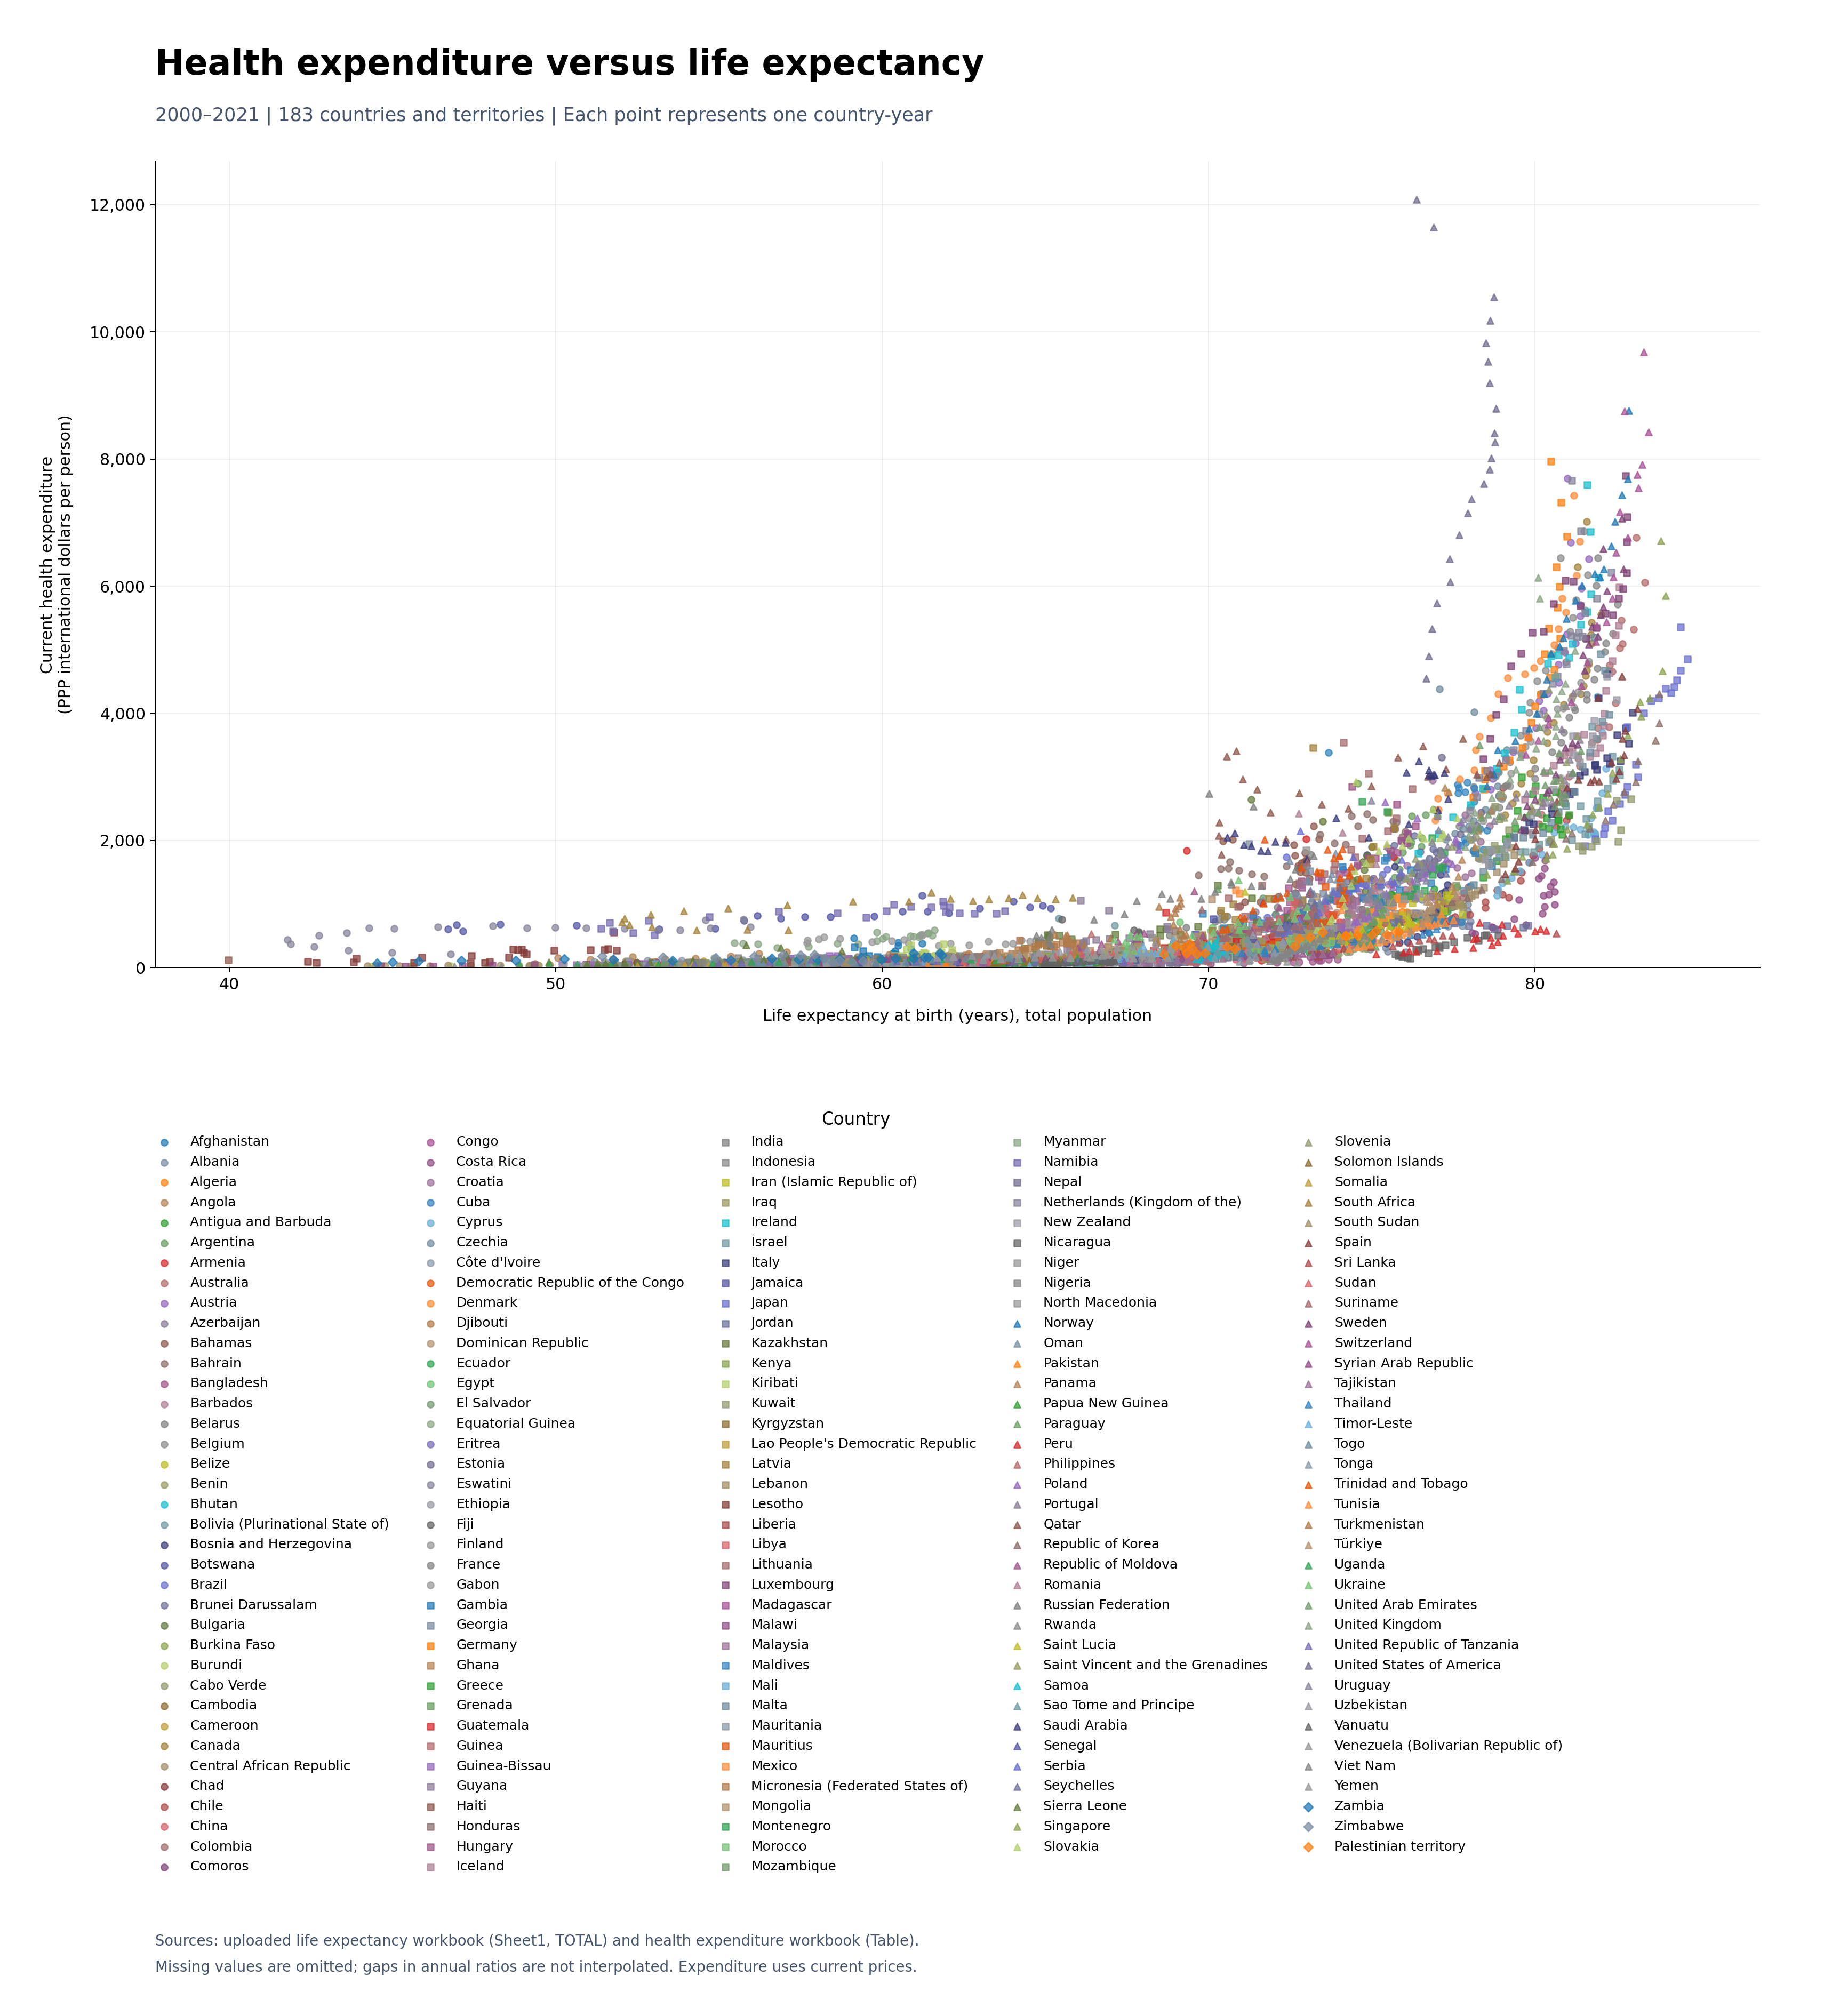

In [ ]:
scatter_path = create_plot('scatter')


## 2. Life expectancy per health expenditure over time

Each line represents one country or territory. The y-axis is logarithmic; equal vertical distances indicate equal proportional changes.


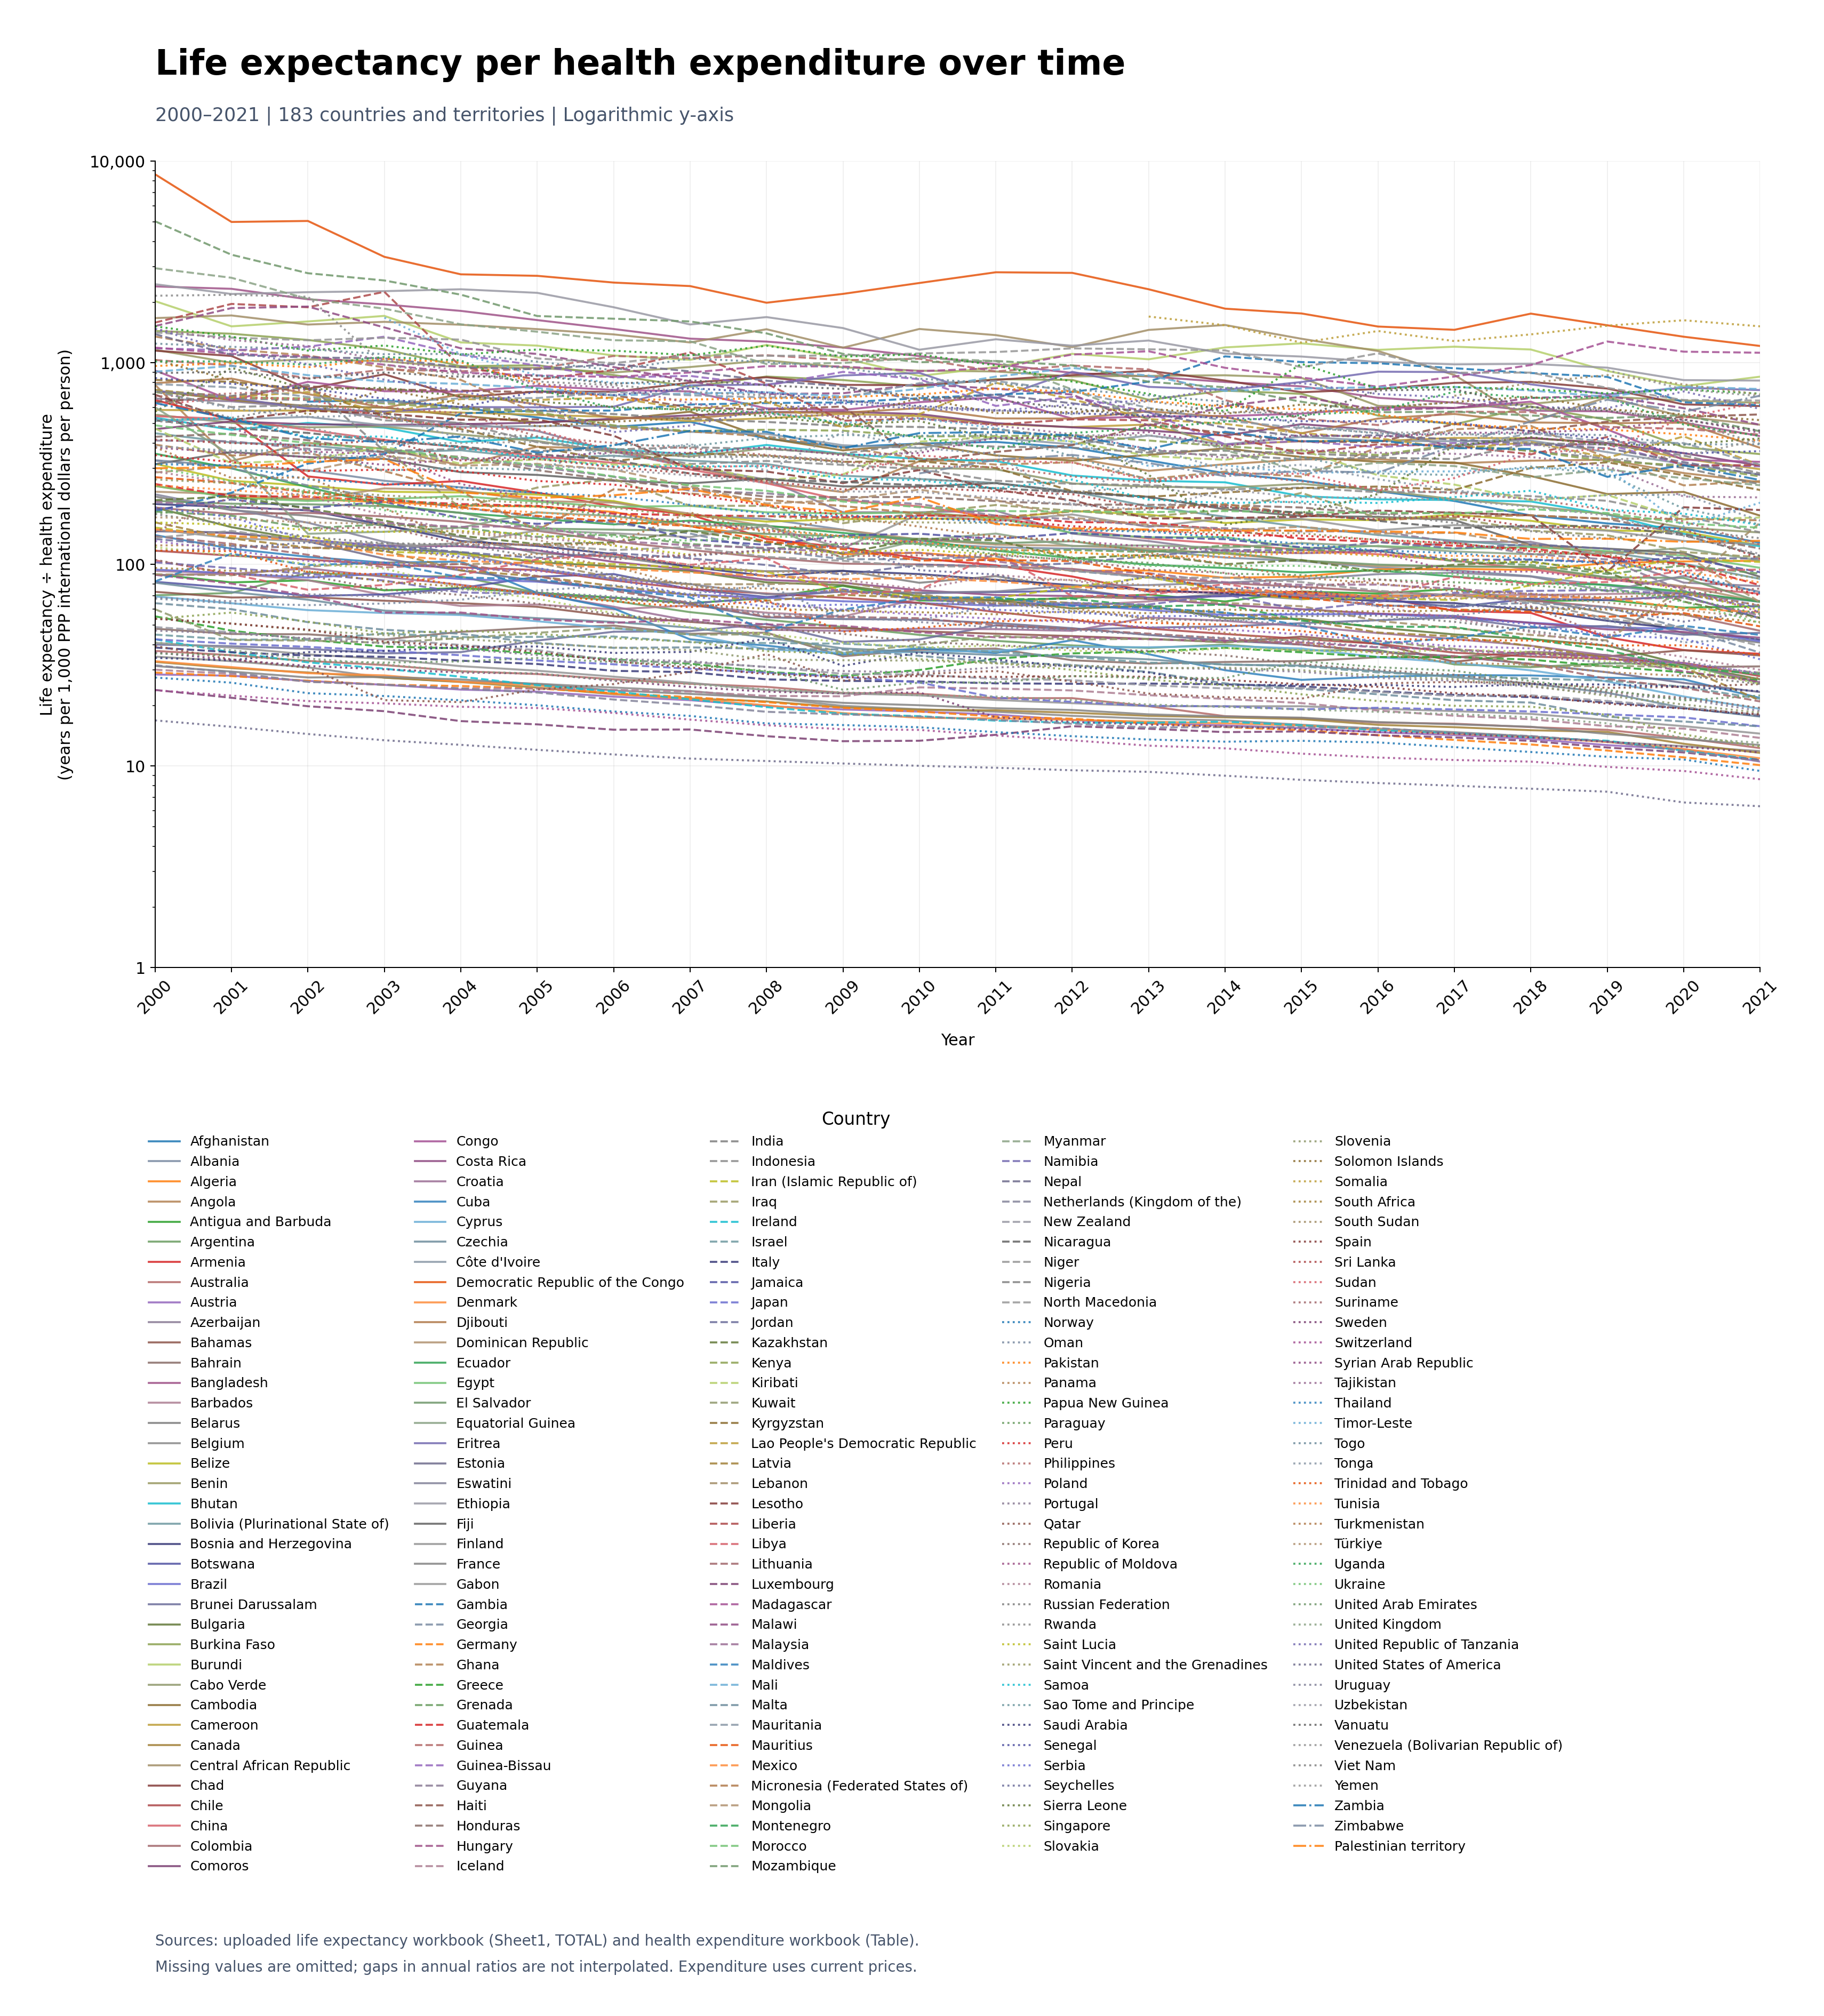

In [ ]:
ratio_path = create_plot('ratio')


## Download both plots

Run this optional cell to download a ZIP containing both PNG files.


In [ ]:
import zipfile
with zipfile.ZipFile("life_expectancy_health_expenditure_plots.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in [scatter_path, ratio_path]:
        archive.write(path, arcname=path.name)
files.download("life_expectancy_health_expenditure_plots.zip")
